<a href="https://colab.research.google.com/github/olivialiljefors/CB2330---Project/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Does genetically raised HDL cholesterol lower the risk of myocardial infarction?
**Klara Gesché & Olivia Liljefors**

**The paper:** Voight et al. (2012). Plasma HDL cholesterol and risk of myocardial infarction: a mendelian randomisation study. *The Lancet*, 380, 572–580.

**The data object:** Figure 2: odds ratios (with 95% confidence intervals) for the association between the LIPG Asn396Ser variant and myocardial infarction (MI). We use the six prospective cohort studies (ARIC, CCHS, DCH, FHS, HPFS, MDC; 50 763 participants, 4228 MI cases).

**The random variable chosen:** $X_j$, the log odds ratio for MI per copy of the HDL-raising Ser allele, as reported for cohort study $j$ ($j = 1, \dots, 6$).

**What the paper does:** The paper tests whether HDL cholesterol *causes* a lower risk of MI, using mendelian randomisation. People who carry the Ser allele have higher HDL from birth. If HDL protects against MI, carriers should have fewer MIs, and the paper predicts an OR of about 0.87 (13% lower risk). The paper combines the studies in a meta-analysis and finds no protective effect (cohort studies: OR 1.10, 95% CI 0.89–1.37).

**The generative model proposed:** All six studies measure the same true effect $\theta$. Each study sees this effect with random noise, because it only has a limited number of participants. Smaller studies are noisier.

$$X_j \sim N(\theta,\ SE_j^2)$$

The standard error of each study is recovered from its 95% confidence interval:

$$SE_j = \frac{\log(\text{upper}_j) - \log(\text{lower}_j)}{2 \cdot 1.96}$$

**Parameters and assumptions:**
- **$\theta$** is the only parameter we estimate: the true log odds ratio for MI per copy of the Ser allele (unitless). $\theta = 0$ means no effect, and $\theta < 0$ means the allele protects against MI.
- **$SE_j$** are not fitted. They are fixed values, calculated from the confidence intervals in Figure 2.

We assume that:
- each study's log(OR) is normally distributed around $\theta$
- all six studies share the same true $\theta$, and the differences between them are only due to random sampling.
- the standard errors calculated from the rounded confidence intervals are accurate enough
- the studies are independent of each other

**The parameterization/fitting:** We estimate $\theta$ from the six real studies by maximum likelihood. We calculate the negative log-likelihood

$$\text{NLL}(\theta) = \sum_{j=1}^{6} \frac{(X_j - \theta)^2}{2\,SE_j^2}$$

for a grid of $\theta$ values and find the minimum. We check that our estimate matches the paper (OR ≈ 1.10). The uncertainty of $\hat\theta$ is estimated from the curvature of the NLL at its minimum.

**The forward simulation:** We simulate the six-study experiment 10 000 times. Each time, we draw six new log(OR) values from $N(\theta,\ SE_j^2)$ and estimate $\theta$ from them using the NLL. This gives a distribution of 10 000 estimates. We run the simulation with two $\theta$ values:
1. $\theta = \hat\theta$ (our fitted value), to see how much the estimate varies between repeated experiments. We compare this spread with the NLL curvature.
2. $\theta = \log(0.87)$, the effect the paper predicts if HDL protects against MI.


**What the model adds to the paper:**
*How likley is it to get the reported log(OR) if the true theta was the predicted log(0.87)?*

From the simulation with the predicted $\theta$ value we get a distribution of all possibles theta values that could have been generated from the six cohort studies. We used this to calculate the probability of getting the reported OR value 1.10 or higher if the true parameter value was actually OR 0.87.

Result: the probability is about 1.6%


**Model limitations/how it breaks:**
- **Common θ:** The true effect might differ between populations (for example Danish and American cohorts). Then the model underestimates the uncertainty.
- With the model we need to assume a common theta for all the studies and the distrubution will always center around the provided theta.

- **Small studies:** The normal approximation may be poor for small studies such as FHS (50 cases).
- **Few studies:** Only six studies are used, and one study (MDC) carries almost half of the total weight.
- **No biology:** The model does not incorporate the biological mechanism (the relationship between HDL levels and risk for MI).

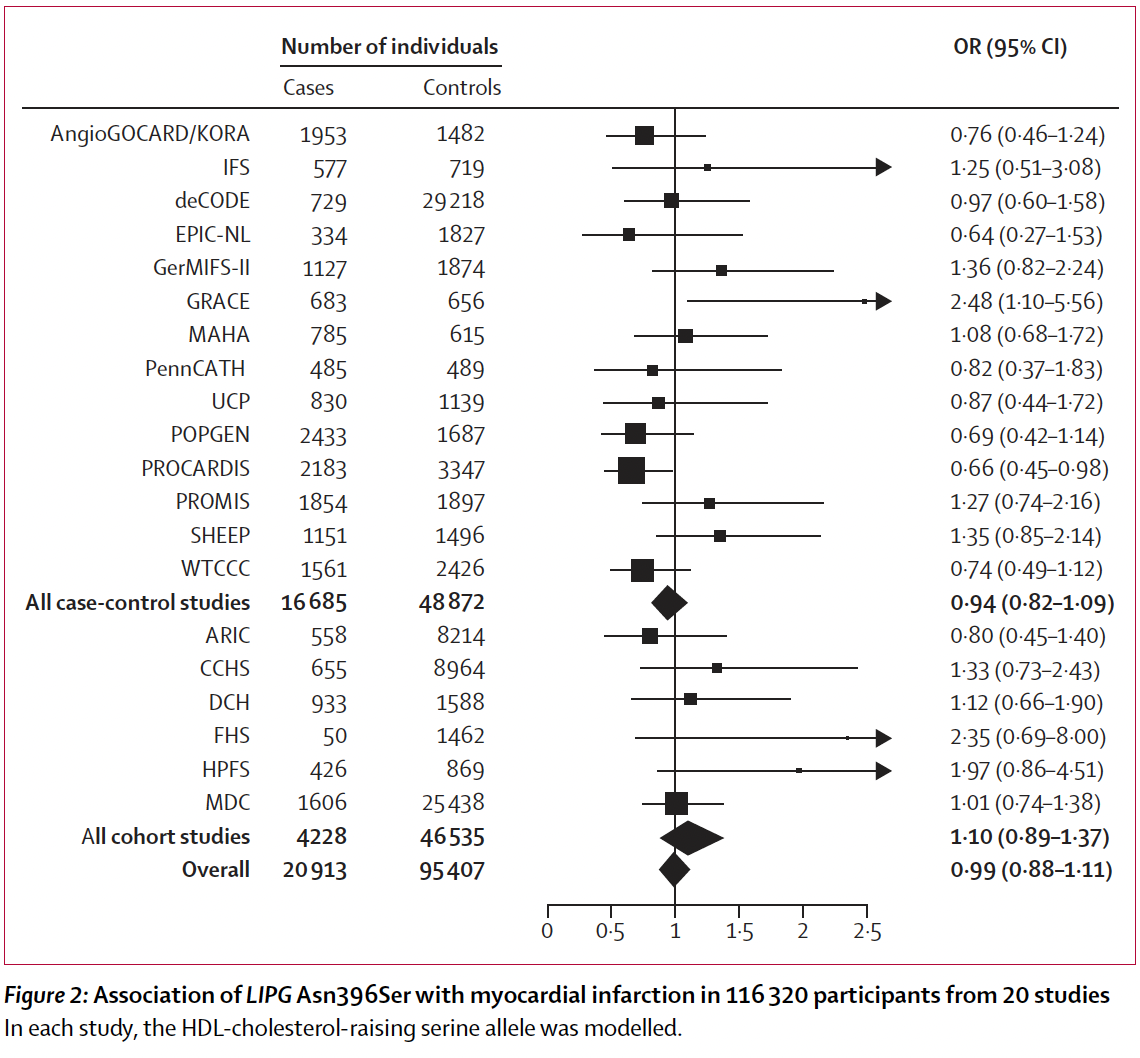

**1. Import the following data from the six cohort studies:**

*   Odds ratio (OR)
*   The confidence intervals (CI)



In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

Study_names = ['ARIC', 'CCHS', 'DCH', 'FHS', 'HPFS', 'MDC']
OR = [0.8, 1.33, 1.12, 2.35, 1.97, 1.01]
Upper_L = [1.4, 2.43, 1.9, 8.0, 4.51, 1.38]
Lower_L = [0.45, 0.73, 0.66, 0.69, 0.86, 0.74]

 **2. Transform the OR and the CI with log**


In [2]:
OR_log = [0.0] * 6
Upper_log = [0.0] * 6
Lower_log = [0.0] * 6

for i in range(len(OR)):
  OR_log[i] = math.log(OR[i])
  Upper_log[i] = math.log(Upper_L[i])
  Lower_log[i] = math.log(Lower_L[i])

In [3]:
OR_log

[-0.2231435513142097,
 0.28517894223366247,
 0.11332868530700327,
 0.8544153281560676,
 0.6780335427498971,
 0.009950330853168092]

**3. Calculate the standard error from the CI**

The standard error of each study is recovered from its 95% confidence interval:

$$SE_j = \frac{\log(\text{upper}_j) - \log(\text{lower}_j)}{2 \cdot 1.96}$$

In [4]:
z = 1.96

def std_error (upper, lower, z):
  """
This function takes the 95% confidence interval and returns a standard error using a normal distribution.
  """
  return (upper - lower) / (z * 2)

In [5]:
SE = [0.0] * 6

for i in range(len(SE)):
  SE[i] = std_error(Upper_log[i], Lower_log[i], z)

for i in range(len(Study_names)):
  print(f"{Study_names[i]}: log(OR) {OR_log[i]}, SE {SE[i]}")

#calculate the log(OR) and SE from the reported common values
log_OR_common = math.log(1.10)
SE_common = std_error(math.log(1.37), math.log(0.89), z)
print(f"All cohort studies: log(OR) {log_OR_common}, SE {SE_common}")

ARIC: log(OR) -0.2231435513142097, SE 0.28953569715280214
CCHS: log(OR) 0.28517894223366247, SE 0.3067862250490197
DCH: log(OR) 0.11332868530700327, SE 0.26973707401379093
FHS: log(OR) 0.8544153281560676, SE 0.6251288834363948
HPFS: log(OR) 0.6780335427498971, SE 0.4227347049105027
MDC: log(OR) 0.009950330853168092, SE 0.15897668162067216
All cohort studies: log(OR) 0.09531017980432493, SE 0.11003687655509824


**4. Define functions for:**


*   Normal distribution
*   NLL for the normal distribution
*   Finding the position of the smallest value


In [6]:
def normal(x, theta, sigma):
    """Normal probability density function f(x | theta, sigma)."""
    return math.exp(-(x - theta) ** 2 / (2 * sigma ** 2)) / (sigma * (2 * math.pi) ** 0.5)

def nll_normal(x, theta, sigma):
    """NLL(theta, sigma) = - the sum over experiments of log f(x_i | theta, sigma)."""
    total = 0.0
    for i, error in zip(x, sigma):
      total = total - math.log(normal(i, theta, error))
    return total

def position_of_min(values):
    """The index of the smallest entry: the position, not the value."""
    best = 0
    for j in range(len(values)):
      if values[j] < values[best]:
        best = j
    return best



**5. Sweep through theta candidates and select the best one**

To find the estimate of theta, the common log(OR), we sweep thourgh a grid of theta values and score each of them using NLL. The values of the candidates covers the range of log(OR) observed across the studies.


In [7]:
def candidate_sweep(n, step_size, starting_point, log_ORs, se):
  """
  Calculate the NLL for a grid of theta candidates. Returns the list of candidates and a list of their scores.
  """
  candidates = [0.0] * n
  candidates[0] = starting_point
  scores = [0.0] * n

  for i in range(n-1):
    candidates[i+1] = candidates[i] + step_size

  for j in range(n):
    scores[j] = nll_normal(log_ORs, candidates[j], se)

  return candidates, scores

In [8]:
n_steps = 300
step_size = 0.005
starting_point = -0.5

candidates, scores = candidate_sweep(n_steps, step_size, starting_point, OR_log, SE)
theta_hat = candidates[position_of_min(scores)]
print(f"testing {len(candidates)} theta candidates; from log(OR)={candidates[0]}, until log(OR)={candidates[-1]}, with step size {step_size} ")
print(f"the best theta candidate is: {theta_hat}")
print(f"the exponential of this is (the OR is): {math.exp(theta_hat)}")

testing 300 theta candidates; from log(OR)=-0.5, until log(OR)=0.9950000000000011, with step size 0.005 
the best theta candidate is: 0.1000000000000004
the exponential of this is (the OR is): 1.1051709180756482


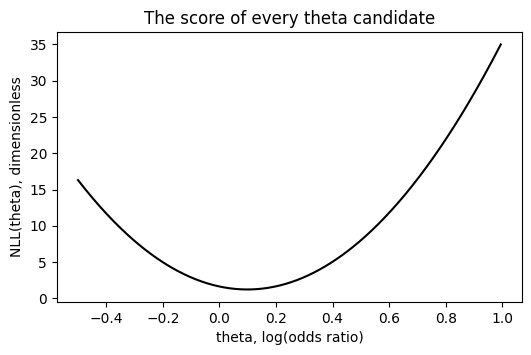

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(candidates, scores, color="black")
ax.set_xlabel("theta, log(odds ratio)")
ax.set_ylabel("NLL(theta), dimensionless")
ax.set_title("The score of every theta candidate")
plt.show()

In [10]:
# Calculate curavture and curvature sd
h = 0.01
curvature = (nll_normal(OR_log, theta_hat + h, SE) - 2 * nll_normal(OR_log, theta_hat, SE) + nll_normal(OR_log, theta_hat-h, SE)) / h**2
sigma_curv = 1/math.sqrt(curvature)
print(f"the curvature is: {curvature}")
print(f"the error is: {sigma_curv}")

the curvature is: 84.01970558526095
the error is: 0.10909614941913877


**6.Simulate with ^$\theta$**


Assuming the ^$\theta$ is the true value for all studies, we simulate the six cohort studies using Monte Carlo. For each simulation, we pull a randum log(OR) value for each of the six studies. All studies have the same parameter theta (the assumed common true value), but their own specific standard error which was calculated from the reported CIs.

In [11]:
def random_normal(theta, se):
  """
  Generates 6 random numbers from a normal distrubution with a mean of theta and the study-specifc standard error se[i]
  """
  log_ORs_random = [0.0] * len(se)
  for i in range(len(log_ORs_random)):
    log_ORs_random[i] = np.random.normal(theta, se[i])
  return log_ORs_random

print(random_normal(theta_hat, SE))

[0.015448655086628571, 0.45863676206531045, 0.14597780511613456, 0.11559866601652113, 0.05751510929065007, -0.16157571272797525]


In [12]:
def simulate(n, theta, se):
  """
  Simulates the six cohart studies and prodcues a list of n estimated thetas.
  Theta is the assumed common parameter (log(OR)) for the six studies, and se is a list of study-specific standard errors.
  """
  theta_hat_sim = [0.0] * n
  for i in range(len(theta_hat_sim)):
    log_ORs_random = random_normal(theta, se)
    candidates, scores = candidate_sweep(400, 0.01, -1, log_ORs_random, se)
    theta_hat_sim[i] = candidates[position_of_min(scores)]
  return theta_hat_sim

In [13]:
# Sanity check: is the mean of the simulated thetas reasonable?
n_simulations = 10000

theta_hat_sim = simulate(n_simulations, theta_hat, SE)
mean_theta_hat = sum(theta_hat_sim)/len(theta_hat_sim)
print(f"the mean of the {n_simulations} estimated thetas is: {mean_theta_hat}")
print(f"the exponential of this is {math.exp(mean_theta_hat)}")

# Spread of the simulated thetas, compared with the uncertainty from the NLL curvature
sd_theta_hat = np.std(theta_hat_sim)
print(f"the standard deviation of the simulated thetas is: {sd_theta_hat}")
print(f"the error from the NLL curvature is: {sigma_curv}")

the mean of the 10000 estimated thetas is: 0.09943500000000076
the exponential of this is 1.1045466728728117
the standard deviation of the simulated thetas is: 0.10919363889439718
the error from the NLL curvature is: 0.10909614941913877


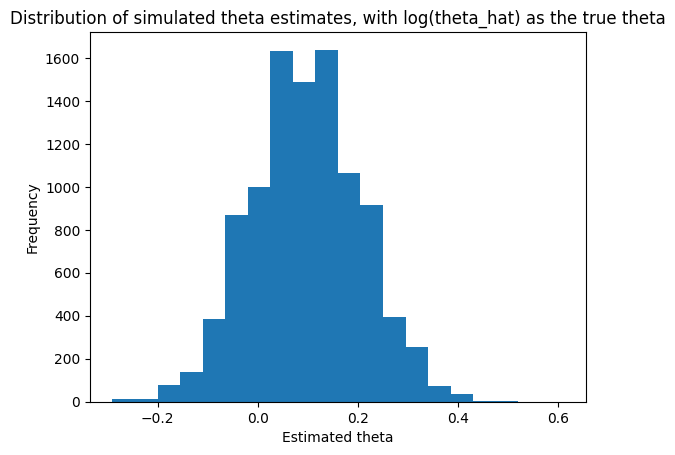

In [14]:
plt.hist(theta_hat_sim, bins=20)
plt.xlabel("Estimated theta")
plt.ylabel("Frequency")
plt.title("Distribution of simulated theta estimates, with log(theta_hat) as the true theta")
plt.show()

7. **Assume that the precidec OR 0.87 is the true value**

If the prediced OR 0.87 is the true value, how likley is it to get OR 1.1?

* Simulate the estimated theta with log(0.87) as the true common theta.
* What does this distrubution look like?
* What is the probality of getting log(1.10) or higher as the theta if log(0.87) is the true value?


In [15]:
# Simulate the six experiments with log(0.87) as the true theta
hyp_theta = math.log(0.87)

hyp_theta_hat_sim = simulate(n_simulations, hyp_theta, SE)
hyp_mean_theta_hat = sum(hyp_theta_hat_sim)/len(hyp_theta_hat_sim)
print(hyp_mean_theta_hat)
print(math.exp(hyp_mean_theta_hat))

-0.13856899999999928
0.8706031775773455


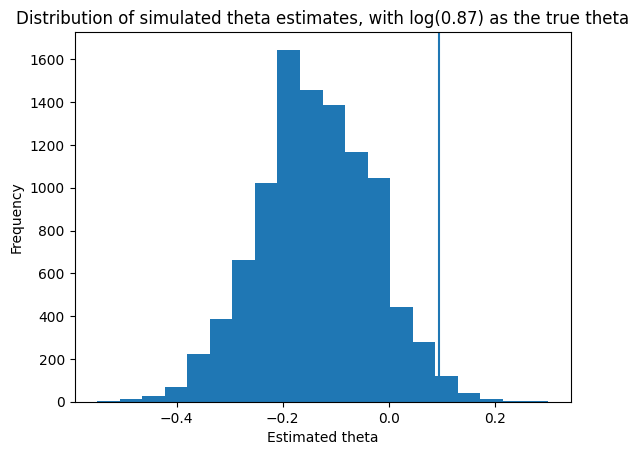

In [16]:

plt.hist(hyp_theta_hat_sim, bins=20)
plt.xlabel("Estimated theta")
plt.ylabel("Frequency")
plt.title("Distribution of simulated theta estimates, with log(0.87) as the true theta")
plt.axvline(math.log(1.10))
plt.show()

In [17]:
# Get prob of getting a theta of log(1.10) or higher from this distrubution

# Count how many values are equal to or above log(1.10)
count = 0

for i in hyp_theta_hat_sim:
  if i >= math.log(1.10):
    count += 1

#Get prob of theta being equal to or log(1.10)

prob = count / len(hyp_theta_hat_sim)
print(f"the probability of getting OR 1.10 or higher if the true value is 0.87 is: {prob}")

the probability of getting OR 1.10 or higher if the true value is 0.87 is: 0.014
